# Laboratorio 3 - La tarea de clasificación

Integrantes: Jose Fonseca, Daniel Galindo

Ruta Alpes quiere identificar, para dos tipos de cupón (Cafetería y Restaurante(<20)), en qué escenarios de
conducción un conductor tiene mayor probabilidad de aceptarlo. Cada fila del conjunto de datos describe un escenario
(destino, hora, clima, acompañantes, distancia al establecimiento) junto con el perfil y los hábitos de consumo del
conductor, y la columna `acepta_cupon` indica si aceptó el cupón ofrecido.

## Exploración de datos

El primer paso del ciclo de machine learning es explorar el conjunto de datos para entender su estructura y detectar
problemas de calidad que deban resolverse antes de construir los modelos. Para empezar se cargan los datos de
entrenamiento, los datos de prueba sin etiquetar y el diccionario de datos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, precision_recall_fscore_support

SEED = 42
CUPONES = ["Cafetería", "Restaurante(<20)"]
COLOR = {"Cafetería": "#2a78d6", "Restaurante(<20)": "#eb6834"}

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

datos = pd.read_excel("data/Lab3_Datos.xlsx")
prueba = pd.read_excel("data/Lab3_datos_Prueba.xlsx")
diccionario = pd.read_excel("data/Lab3_diccionario_Datos.xlsx")
print("datos:", datos.shape, "| prueba (sin etiqueta):", prueba.shape)
datos.head()
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from IPython.display import display
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)


datos: (12664, 26) | prueba (sin etiqueta): (20, 25)


El conjunto de entrenamiento tiene 12.664 escenarios y 26 columnas, de las cuales 25 son variables de entrada y una es
la variable objetivo. Los datos de prueba tienen 20 escenarios con las mismas variables de entrada y sin etiqueta.

### Tipos estadísticos de las columnas

A partir del diccionario de datos se identifica el tipo estadístico de cada columna, lo cual define más adelante cómo
debe codificarse.

In [2]:
print(datos.dtypes.value_counts().to_string())
diccionario[["Variable", "Tipo"]]

str      25
int64     1


,Variable,Tipo
0,destino,Categórica nominal
1,acompanante,Categórica nominal
2,clima,Categórica nominal
3,temperatura,Numérica entero
4,hora,Categórica ordinal
5,cupon,Categórica nominal
6,vigencia_cupon,Categórica nominal
7,genero,Categórica nominal
8,edad,Categórica ordinal
9,estado_civil,Categórica nominal


Todas las columnas están almacenadas como texto excepto `temperatura`. Esto incluye a las variables ordinales
(`hora`, `edad`, `educacion`, `ingreso` y las cinco `frecuencia_*`), cuyo orden se pierde si se tratan como texto. Por
lo tanto, en la preparación será necesario codificarlas respetando el orden que indica el diccionario. Las demás
variables categóricas son nominales y las de tipo Sí/No son binarias.

### Evaluación de las 4 dimensiones de calidad de datos

Una vez identificados los tipos de las columnas se revisan las cuatro dimensiones de calidad: completitud (valores
nulos), unicidad (registros duplicados), consistencia (formatos y relaciones coherentes entre columnas) y validez
(valores dentro de los rangos esperados). Como los modelos se construyen por separado para cada cupón, los resultados
se reportan también para cada subconjunto.

#### Completitud

In [3]:
faltantes = pd.DataFrame({"faltantes": datos.isna().sum(), "%": (100 * datos.isna().mean()).round(2)})
faltantes = faltantes[faltantes["faltantes"] > 0].sort_values("faltantes", ascending=False)
for cupon in CUPONES:
    sub = datos[datos["cupon"] == cupon]
    faltantes[f"% en {cupon}"] = (100 * sub[faltantes.index].isna().mean()).round(2)
faltantes

,faltantes,%,% en Cafetería,% en Restaurante(<20)
vehiculo,12556,99.15,99.07,99.10
frecuencia_cafeteria,217,1.71,1.81,1.69
frecuencia_restaurante_20_a_50,189,1.49,1.38,1.55
frecuencia_comida_para_llevar,151,1.19,1.43,1.22
frecuencia_restaurante_menos_20,130,1.03,1.25,0.97
frecuencia_bar,107,0.84,0.93,0.83


La columna `vehiculo` está vacía en el 99,1 % de los escenarios: solo 108 de 12.664 registros tienen un valor, por lo
que no es posible imputarla sin inventar casi toda la columna. Por otro lado, las cinco variables de frecuencia de
consumo tienen entre 0,8 % y 1,8 % de valores nulos, con proporciones muy parecidas en los dos subconjuntos. Al ser
pocos, estos valores sí pueden completarse en la preparación aunque imputar la moda puede aumentar ligeramente la frecuencia de la categoría mayoritaria. El resto de
columnas está completo.

#### Unicidad

In [4]:
for cupon in CUPONES:
    sub = datos[datos["cupon"] == cupon]
    x = sub.drop(columns="acepta_cupon")
    print(f"{cupon}: {sub.duplicated().sum()} duplicados exactos | "
          f"{x.duplicated(keep=False).sum() - sub.duplicated(keep=False).sum()} filas con las mismas variables "
          f"y distinta etiqueta")

Cafetería: 7 duplicados exactos | 8 filas con las mismas variables y distinta etiqueta
Restaurante(<20): 7 duplicados exactos | 6 filas con las mismas variables y distinta etiqueta


Cada subconjunto tiene 7 filas duplicadas exactamente, es decir, con las mismas variables y la misma etiqueta. Si una
copia queda en el conjunto de entrenamiento y otra en el de prueba, el modelo se evalúa con un escenario que ya vio,
por lo que deben eliminarse. Además, hay unas pocas filas con las mismas variables pero distinta etiqueta (8 en
Cafetería y 6 en Restaurante). Estas no se consideran un error, ya que dos conductores con el mismo perfil y en el mismo
escenario pueden tomar decisiones distintas; reflejan el ruido propio de la variable objetivo.

#### Consistencia

In [5]:
print("Columnas con menos de 3 valores distintos:")
print(datos.nunique().loc[lambda s: s < 3].to_string(), "\n")
print(pd.crosstab(datos["misma_direccion"], datos["direccion_opuesta"]), "\n")
print(pd.crosstab(datos["tiempo_cupon_mayor_15min"], datos["tiempo_cupon_mayor_25min"]), "\n")
print(pd.crosstab(datos["clima"], datos["temperatura"]))

Columnas con menos de 3 valores distintos:
vigencia_cupon              2
genero                      2
tiene_hijos                 2
tiempo_cupon_mayor_5min     1
tiempo_cupon_mayor_15min    2
tiempo_cupon_mayor_25min    2
misma_direccion             2
direccion_opuesta           2
acepta_cupon                2 

direccion_opuesta    No    Sí
misma_direccion              
No                    0  9944
Sí                 2720     0 

tiempo_cupon_mayor_25min    No    Sí
tiempo_cupon_mayor_15min            
No                        5551     0
Sí                        5602  1511 

temperatura    30    55    80
clima                        
Lluvioso        0  1208     0
Nevado       1404     0     0
Soleado       911  2628  6513


La variable `tiempo_cupon_mayor_5min` toma siempre el valor Sí, de modo que no aporta información para distinguir
entre escenarios. La variable `direccion_opuesta` es exactamente el complemento de `misma_direccion`, como muestra la
tabla cruzada, por lo que es redundante y basta con conservar una de las dos. En cambio, `tiempo_cupon_mayor_15min` y
`tiempo_cupon_mayor_25min` están anidadas pero no son redundantes, ya que juntas describen tres niveles de distancia
(hasta 15, entre 15 y 25 y más de 25 minutos). Algo similar ocurre con `clima` y `temperatura`: el clima lluvioso
siempre corresponde a 55 °F y el nevado a 30 °F, pero el soleado toma los tres valores, así que ambas aportan
información.

In [6]:
print(pd.crosstab(datos["destino"], datos["hora"]), "\n")
for cupon in CUPONES:
    sub = datos[datos["cupon"] == cupon]
    n = ((sub["acompanante"] == "Hijo(s)") & (sub["tiene_hijos"] == "No")).sum()
    print(f"{cupon}: {n} escenarios con acompañante 'Hijo(s)' y tiene_hijos = 'No'")

hora               10:00 a.m.  10:00 p.m.  2:00 p.m.  6:00 p.m.  7:00 a.m.
destino                                                                   
Casa                        0        1113          0       2120          0
Sin lugar urgente        2271         890       2005       1104          0
Trabajo                     0           0          0          0       3161 

Cafetería: 4 escenarios con acompañante 'Hijo(s)' y tiene_hijos = 'No'
Restaurante(<20): 3 escenarios con acompañante 'Hijo(s)' y tiene_hijos = 'No'


El destino y la hora están muy ligados por el diseño de la encuesta (por ejemplo, el destino Trabajo solo aparece a
las 7:00 a.m.), lo que hará difícil separar el efecto de una variable del de la otra. También se encontraron unos
pocos escenarios (4 en Cafetería y 3 en Restaurante) en los que el conductor va con sus hijos pero reporta no tenerlos.
Puede tratarse de un error de registro o de niños que no son propios; al ser tan pocos casos, se conservan.

#### Validez

In [7]:
for col in datos.columns.drop(["ocupacion", "acepta_cupon"]):
    print(f"{col}: {sorted(datos[col].dropna().astype(str).unique())}")

destino: ['Casa', 'Sin lugar urgente', 'Trabajo']
acompanante: ['Amigo(s)', 'Hijo(s)', 'Pareja', 'Solo']
clima: ['Lluvioso', 'Nevado', 'Soleado']
temperatura: ['30', '55', '80']
hora: ['10:00 a.m.', '10:00 p.m.', '2:00 p.m.', '6:00 p.m.', '7:00 a.m.']
cupon: ['Bar', 'Cafetería', 'Comida para llevar', 'Restaurante(20-50)', 'Restaurante(<20)']
vigencia_cupon: ['1 día', '2 horas']
genero: ['Femenino', 'Masculino']
edad: ['21', '26', '31', '36', '41', '46', '50 o más', 'menor de 21']
estado_civil: ['Casado(a)', 'Divorciado(a)', 'Soltero(a)', 'Unión libre', 'Viudo(a)']
tiene_hijos: ['No', 'Sí']
educacion: ['Bachillerato completo', 'Bachillerato incompleto', 'Estudios universitarios sin título', 'Posgrado (Maestría o Doctorado)', 'Pregrado', 'Técnico/Tecnólogo']
ingreso: ['$100.000 o más', '$12.500 - $24.999', '$25.000 - $37.499', '$37.500 - $49.999', '$50.000 - $62.499', '$62.500 - $74.999', '$75.000 - $87.499', '$87.500 - $99.999', 'Menos de $12.500']
vehiculo: ['Camioneta tipo crossover',

Todos los valores coinciden con los descritos en el diccionario de datos y no se encontraron formatos inconsistentes,
como mayúsculas o espacios distintos para una misma categoría. La `temperatura` solo toma los tres valores esperados
(30, 55 y 80). La única excepción de formato es una categoría informal de `vehiculo` ("Carro muy viejo para instalarle
Onstar :D"), que no tiene efecto porque esa columna se eliminará. Por último, `ocupacion` tiene 25 categorías, varias
con muy pocos casos, lo que se tendrá en cuenta al codificarla.

No se recortan valores atípicos: las temperaturas de 30, 55 y 80 °F son niveles válidos del diseño, y las categorías poco frecuentes no se consideran errores por ser raras.

### Distribución de la variable objetivo en cada subconjunto

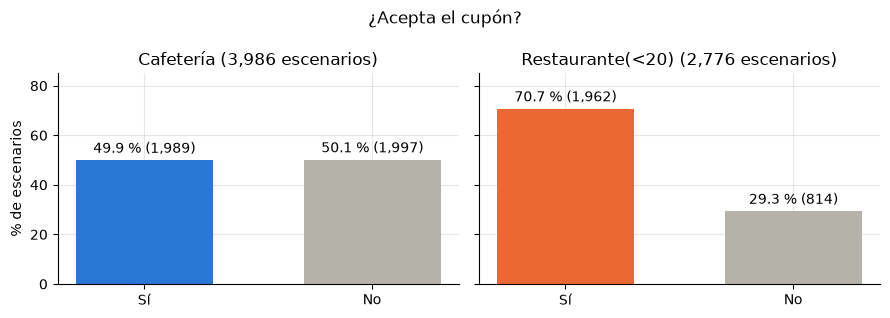

acepta_cupon,Sí,No,total,% Sí
Cafetería,1989,1997,3986,49.9
Restaurante(<20),1962,814,2776,70.7


In [8]:
subconjuntos = {c: datos[datos["cupon"] == c].copy() for c in CUPONES}
distribucion = pd.DataFrame({c: s["acepta_cupon"].value_counts() for c, s in subconjuntos.items()}).T[["Sí", "No"]]
distribucion["total"] = distribucion.sum(axis=1)
distribucion["% Sí"] = (100 * distribucion["Sí"] / distribucion["total"]).round(1)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (cupon, fila) in zip(axes, distribucion.iterrows()):
    pct = 100 * fila[["Sí", "No"]] / fila["total"]
    barras = ax.bar(pct.index, pct.values, color=[COLOR[cupon], "#b4b2a9"], width=0.6)
    ax.bar_label(barras, labels=[f"{v:.1f} % ({int(n):,})" for v, n in zip(pct, fila[["Sí", "No"]])], padding=3)
    ax.set_title(f"{cupon} ({int(fila['total']):,} escenarios)")
    ax.set_ylim(0, 85)
axes[0].set_ylabel("% de escenarios")
fig.suptitle("¿Acepta el cupón?")
plt.tight_layout()
plt.show()
distribucion

El subconjunto de Cafetería (3.986 escenarios) está balanceado, con 49,9 % de aceptaciones y 50,1 % de rechazos. En
cambio, el de Restaurante(<20) (2.776 escenarios) está desbalanceado: el 70,7 % de los conductores acepta el cupón y
solo el 29,3 % lo rechaza, de modo que la clase minoritaria es No.

Este desbalance tiene dos consecuencias. La primera es que en Restaurante un modelo que siempre prediga Sí ya
alcanzaría una exactitud de 70,7 %, por lo que la accuracy no es una buena métrica y se deben revisar la precisión, el
recall y el F1-score de cada clase, en especial el recall de la clase No. La segunda es que la división en
entrenamiento y prueba y la validación cruzada deben ser estratificadas, para que ambas clases conserven su proporción
en cada partición.

### Visualización de la aceptación según el contexto

Para tener una primera idea de qué variables podrían ser informativas, se compara la proporción de aceptación según
los valores de algunas variables del contexto y del hábito de consumo del conductor.

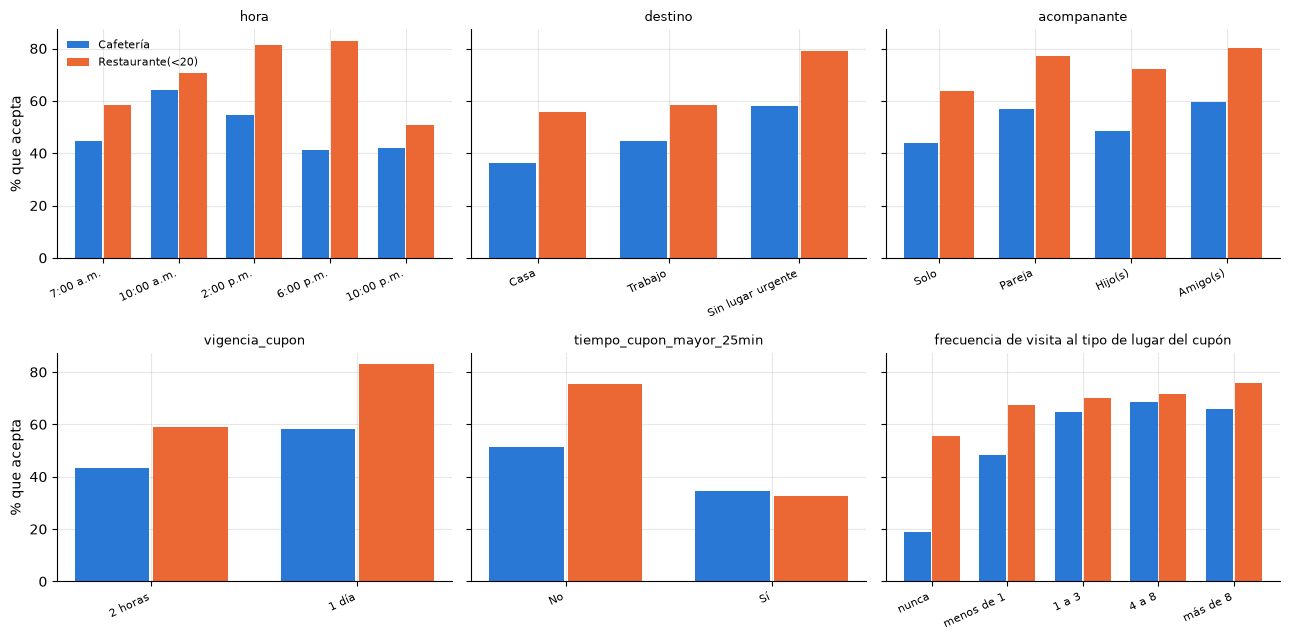

In [9]:
ORDEN_HORA = ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."]
ORDEN_FRECUENCIA = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
GRAFICOS = [
    ("hora", ORDEN_HORA),
    ("destino", ["Casa", "Trabajo", "Sin lugar urgente"]),
    ("acompanante", ["Solo", "Pareja", "Hijo(s)", "Amigo(s)"]),
    ("vigencia_cupon", ["2 horas", "1 día"]),
    ("tiempo_cupon_mayor_25min", ["No", "Sí"]),
    ("frecuencia propia", ORDEN_FRECUENCIA),
]
FRECUENCIA_PROPIA = {"Cafetería": "frecuencia_cafeteria", "Restaurante(<20)": "frecuencia_restaurante_menos_20"}

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (variable, orden) in zip(axes.flat, GRAFICOS):
    x = np.arange(len(orden))
    for k, (cupon, sub) in enumerate(subconjuntos.items()):
        col = FRECUENCIA_PROPIA[cupon] if variable == "frecuencia propia" else variable
        tasa = sub.groupby(col)["acepta_cupon"].apply(lambda s: (s == "Sí").mean()).reindex(orden)
        ax.bar(x + (k - 0.5) * 0.38, 100 * tasa.values, width=0.36, color=COLOR[cupon], label=cupon)
    ax.set_xticks(x, orden, rotation=25, ha="right", fontsize=8)
    ax.set_title(variable if variable != "frecuencia propia" else "frecuencia de visita al tipo de lugar del cupón",
                 fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("% que acepta")
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

La variable que muestra la mayor diferencia es el hábito de consumo: en Cafetería, los conductores que nunca van a una
cafetería aceptan el cupón solo el 19 % de las veces, frente a un 65 %–69 % de quienes van al menos una vez al mes.
En Restaurante este efecto también existe, aunque es menor. La distancia también muestra una asociación clara, ya que cuando
el establecimiento está a más de 25 minutos la aceptación baja de 51 % a 35 % en Cafetería y de 75 % a 33 % en
Restaurante. Además, los cupones con vigencia de un día se aceptan más que los de dos horas, y la aceptación es mayor
cuando el conductor no tiene un lugar urgente al que llegar. En cuanto a la hora, Cafetería se acepta más a las
10:00 a.m. y Restaurante a las 2:00 p.m. y 6:00 p.m., lo que es coherente con los horarios de cada tipo de lugar. Por
el contrario, las variables demográficas como el género muestran diferencias mucho menores (49 % frente a 51 % en
Cafetería), lo cual será relevante para el análisis de sesgo.

### Datos de prueba

In [10]:
print("Cupones:", prueba["cupon"].value_counts().to_dict())
print("Mismas columnas que los datos (sin acepta_cupon):",
      list(prueba.columns) == [c for c in datos.columns if c != "acepta_cupon"])
print("Faltantes:", prueba.isna().sum().loc[lambda s: s > 0].to_dict())
nuevos = {c: set(prueba[c].dropna()) - set(datos[c].dropna()) for c in prueba.columns}
print("Valores que no aparecen en los datos de entrenamiento:", {c: v for c, v in nuevos.items() if v} or "ninguno")

Cupones: {'Cafetería': 10, 'Restaurante(<20)': 10}
Mismas columnas que los datos (sin acepta_cupon): True
Faltantes: {'vehiculo': 20}
Valores que no aparecen en los datos de entrenamiento: ninguno


Los datos de prueba tienen 10 escenarios de cada cupón, las mismas columnas que el conjunto de entrenamiento, ningún
valor que no aparezca en él y faltantes únicamente en `vehiculo`. Por lo tanto, la preparación que se defina a
continuación se les puede aplicar sin cambios.

### Conclusión exploración

En resumen, la exploración encontró problemas en las cuatro dimensiones de calidad. En completitud, la columna
`vehiculo` está casi vacía y las variables de frecuencia tienen un pequeño porcentaje de nulos. En unicidad, hay 7
filas duplicadas en cada subconjunto. En consistencia, se identificó una columna constante, una columna redundante y
algunos casos aislados de información contradictoria. En validez, los valores corresponden al diccionario, pero las
variables ordinales están guardadas como texto. Por último, el subconjunto de Restaurante(<20) presenta un desbalance
de clases (70,7 % / 29,3 %) que condiciona la elección de métricas y la forma de dividir los datos. Estos hallazgos
guían las decisiones de la siguiente etapa.

## Preparación de los datos

Las decisiones de preparación se dividen en dos grupos. Las que no aprenden nada de los datos (eliminar columnas y
duplicados) se aplican antes de dividir el conjunto. Las que sí aprenden de los datos, como la imputación y la
codificación, se incluyen dentro de un pipeline, de manera que en cada partición de la validación cruzada se ajusten
solo con los datos de entrenamiento y no haya fuga de información desde el conjunto de prueba.

### Eliminación de columnas y duplicados

In [11]:
COLUMNAS_ELIMINAR = ["vehiculo", "tiempo_cupon_mayor_5min", "direccion_opuesta", "cupon"]


def limpiar(df):
    """Elimina columnas sin información o redundantes. Se aplica igual a los datos y al archivo de prueba."""
    return df.drop(columns=COLUMNAS_ELIMINAR)


def preparar_subconjunto(cupon):
    """Filtra un tipo de cupón, limpia, quita duplicados exactos y separa X e y (1 = acepta)."""
    sub = limpiar(datos[datos["cupon"] == cupon]).drop_duplicates()
    return sub.drop(columns="acepta_cupon"), (sub["acepta_cupon"] == "Sí").astype(int)


for cupon in CUPONES:
    X, y = preparar_subconjunto(cupon)
    print(f"{cupon}: {X.shape[0]:,} escenarios × {X.shape[1]} variables | % acepta = {100 * y.mean():.1f}")

Cafetería: 3,979 escenarios × 21 variables | % acepta = 49.8
Restaurante(<20): 2,769 escenarios × 21 variables | % acepta = 70.7


Se eliminan cuatro columnas. La columna `vehiculo` se descarta porque tiene más del 99 % de valores nulos, y
`tiempo_cupon_mayor_5min` porque es constante. La columna `direccion_opuesta` se elimina por ser redundante con
`misma_direccion`, y `cupon` porque, una vez separado cada subconjunto, toma un solo valor. Después se eliminan los
duplicados exactos, conservando las filas con las mismas variables y distinta etiqueta por las razones expuestas en la
exploración. La variable objetivo se codifica como 1 cuando el conductor acepta el cupón y 0 cuando lo rechaza. Tras
este paso quedan 3.979 escenarios en Cafetería y 2.769 en Restaurante, con 21 variables de entrada cada uno.

### Tratamiento de nulos y codificación de variables

Cada tipo de variable recibe un tratamiento distinto mediante un `ColumnTransformer`, siguiendo el orden de categorías
indicado en el diccionario de datos.

In [12]:
ORDINALES = {
    "hora": ORDEN_HORA,
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
                "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
                "$100.000 o más"],
    **{f: ORDEN_FRECUENCIA for f in ["frecuencia_bar", "frecuencia_cafeteria", "frecuencia_comida_para_llevar",
                                     "frecuencia_restaurante_menos_20", "frecuencia_restaurante_20_a_50"]},
    "vigencia_cupon": ["2 horas", "1 día"],
    **{b: ["No", "Sí"] for b in ["tiene_hijos", "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min",
                                 "misma_direccion"]},
}
NOMINALES = ["destino", "acompanante", "clima", "genero", "estado_civil", "ocupacion"]
NUMERICAS = ["temperatura"]


def crear_preprocesador(escalar=False):
    """Imputación + codificación por tipo de columna. escalar=True agrega StandardScaler (regresión logística)."""
    ordinales = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OrdinalEncoder(categories=list(ORDINALES.values()),
                                     handle_unknown="use_encoded_value", unknown_value=-1)),
    ])
    nominales = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    columnas = ColumnTransformer([
        ("ordinales", ordinales, list(ORDINALES)),
        ("nominales", nominales, NOMINALES),
        ("numericas", "passthrough", NUMERICAS),
    ], verbose_feature_names_out=False)
    pasos = [("columnas", columnas)] + ([("escalar", StandardScaler())] if escalar else [])
    return Pipeline(pasos)

Los valores nulos de las variables de frecuencia se completan con la moda. Se eligió la moda porque son variables
categóricas, en las que no tiene sentido usar la media, y porque los nulos representan menos del 2 % de cada columna.
Eliminar las filas con algún nulo, en cambio, implicaría perder cerca del 4,5 % de los escenarios. La moda se calcula
dentro del pipeline, solo con los datos de entrenamiento.

Las variables ordinales se codifican con `OrdinalEncoder` usando el orden del diccionario, de forma que, por ejemplo,
una frecuencia de "4 a 8" visitas quede por encima de "1 a 3". Las variables binarias Sí/No se codifican de la misma
manera como 0 y 1. Las variables nominales (destino, acompañante, clima, género, estado civil y ocupación) se
codifican con `OneHotEncoder`, ya que asignarles números inventaría un orden que no existe; se usa
`handle_unknown="ignore"` para que una categoría no vista en entrenamiento no genere un error. La temperatura se
mantiene como numérica.

Por último, el escalado con `StandardScaler` solo se aplica en los modelos de regresión logística, porque su
regularización penaliza los coeficientes y depende de la escala de las variables. Los árboles de decisión y Random
Forest dividen por umbrales y no se ven afectados por la escala. Las variables demográficas se conservan, ya que el
caso pide evaluar precisamente el riesgo de sesgo de usarlas.

**Supuestos y límites de la representación:** conservar el orden no significa que las distancias entre niveles sean iguales. En logística, los códigos de edad, ingreso o frecuencia imponen un cambio lineal por nivel; la hora también se representa como ordinal aunque el día sea cíclico. Se conserva este enfoque del desarrollo inicial para no alterar la comparación. No se debe interpretar un coeficiente como efecto causal ni concluir que guardar categorías como texto sea un error de validez.

### División en entrenamiento y prueba

In [13]:
particiones = {}
for cupon in CUPONES:
    X, y = preparar_subconjunto(cupon)
    particiones[cupon] = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

pd.DataFrame([{"cupón": c, "entrenamiento": len(p[0]), "prueba": len(p[1]),
               "% acepta (entrenamiento)": round(100 * p[2].mean(), 1),
               "% acepta (prueba)": round(100 * p[3].mean(), 1)} for c, p in particiones.items()])

,cupón,entrenamiento,prueba,% acepta (entrenamiento),% acepta (prueba)
0,Cafetería,3183,796,49.8,49.9
1,Restaurante(<20),2215,554,70.7,70.8


Cada subconjunto se divide en 80 % para entrenamiento y 20 % para prueba, con semilla 42. La división es
estratificada, por lo que la proporción de aceptación se mantiene prácticamente igual en ambas partes (49,8 % y
49,9 % en Cafetería; 70,7 % y 70,8 % en Restaurante). La búsqueda de hiperparámetros de las siguientes actividades se
hará con validación cruzada sobre el conjunto de entrenamiento, y el conjunto de prueba se reservará para la
comparación final de los modelos.

### Verificación del preprocesamiento

In [14]:
X_tr, X_te, y_tr, y_te = particiones["Restaurante(<20)"]
pre = crear_preprocesador().fit(X_tr)
M_tr, M_te = pre.transform(X_tr), pre.transform(X_te)
nombres = pre.get_feature_names_out()

assert not np.isnan(M_tr).any() and not np.isnan(M_te).any(), "quedaron valores faltantes"
assert M_tr.shape[1] == M_te.shape[1] == len(nombres)
print(f"{X_tr.shape[1]} variables originales -> {len(nombres)} columnas numéricas, sin faltantes")
pd.DataFrame(M_tr[:3], columns=nombres)

21 variables originales -> 57 columnas numéricas, sin faltantes


,hora,edad,educacion,ingreso,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,vigencia_cupon,tiene_hijos,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,destino_Casa,destino_Sin lugar urgente,destino_Trabajo,acompanante_Amigo(s),acompanante_Hijo(s),acompanante_Pareja,...,ocupacion_Computación y Matemáticas,ocupacion_Construcción y Extracción,ocupacion_Cuidado Personal y Servicios,ocupacion_Desempleado(a),"ocupacion_Educación, Formación y Bibliotecología",ocupacion_Estudiante,ocupacion_Gerencia,"ocupacion_Instalación, Mantenimiento y Reparación",ocupacion_Jubilado(a),ocupacion_Limpieza y Mantenimiento de Edificios,ocupacion_Negocios y Finanzas,ocupacion_Preparación y Servicio de Alimentos,ocupacion_Producción,ocupacion_Profesionales y Técnicos de la Salud,ocupacion_Servicios Comunitarios y Sociales,ocupacion_Servicios de Protección y Seguridad,ocupacion_Transporte y Manejo de Materiales,ocupacion_Ventas y afines,ocupacion_Área Legal,temperatura
0,4.0,4.0,4.0,8.0,1.0,0.0,2.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0
1,2.0,5.0,5.0,4.0,0.0,2.0,2.0,2.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,80.0
2,0.0,7.0,1.0,1.0,0.0,0.0,3.0,2.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0


Al ajustar el preprocesador con los datos de entrenamiento, las 21 variables de entrada se convierten en 57 columnas
numéricas: 14 de las variables ordinales y binarias, 42 de la codificación one-hot de las variables nominales (la
mayoría de ellas de `ocupacion`) y la temperatura. No quedan valores nulos, y los conjuntos de entrenamiento y prueba
tienen las mismas columnas. Este preprocesador será el primer paso de los pipelines de las actividades 3 a 5, con
escalado en el caso de la regresión logística.

## Construcción de los modelos

### Estrategia de validación y métrica de selección

Para cada algoritmo y cada tipo de cupón se construye un pipeline que une el preprocesamiento definido en la sección
anterior con el modelo. Los hiperparámetros se eligen con `GridSearchCV`, usando validación cruzada estratificada de
10 particiones sobre el conjunto de entrenamiento. El conjunto de prueba solo se usa al final, para reportar el
rendimiento del mejor modelo.

Como métrica para elegir los hiperparámetros se usa el F1-score macro, que promedia el F1 de las dos clases. Se
prefirió frente al F1 de la clase positiva porque en Restaurante(<20), donde el 70,7 % de los escenarios son
aceptaciones, un modelo que siempre predijera Sí obtendría un F1 de 0,83 para esa clase sin reconocer ningún rechazo.
El F1 macro, en cambio, penaliza ese comportamiento porque el F1 de la clase No sería 0. Para Cafetería, que está
balanceada, ambas métricas llevan a conclusiones similares, y usar la misma en los dos subconjuntos facilita la
comparación.

In [15]:
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
resultados_prueba = []


def buscar(pipeline, grilla, cupon):
    """Búsqueda de hiperparámetros con validación cruzada sobre el entrenamiento del cupón."""
    X_tr, X_te, y_tr, y_te = particiones[cupon]
    busqueda = GridSearchCV(pipeline, grilla, cv=kfold, scoring="f1_macro", return_train_score=True, n_jobs=2)
    return busqueda.fit(X_tr, y_tr)


def resumen_busqueda(busqueda, n=3):
    """Mejores combinaciones de la búsqueda, con el F1 macro de entrenamiento y de validación."""
    res = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in res.columns if c.startswith("param_")]
    tabla = res[params + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].copy()
    tabla.columns = [c.replace("param_modelo__", "") for c in tabla.columns]
    if "l1_ratio" in tabla:
        tabla.insert(0, "regularizacion", tabla["l1_ratio"].map({0: "L2", 1: "L1", 0.5: "Elastic net"}))
    print("Mejores hiperparámetros:", busqueda.best_params_)
    print(f"F1 macro promedio en validación cruzada: {busqueda.best_score_:.4f}")
    return tabla.sort_values("rank_test_score").head(n).round(4)


def evaluar_en_prueba(busqueda, cupon, algoritmo):
    """Reporte de clasificación del mejor modelo sobre el conjunto de prueba."""
    X_tr, X_te, y_tr, y_te = particiones[cupon]
    pred = busqueda.best_estimator_.predict(X_te)
    print(classification_report(y_te, pred, target_names=["No acepta (0)", "Acepta (1)"], digits=3))
    p, r, f, _ = precision_recall_fscore_support(y_te, pred, labels=[0, 1], zero_division=0)
    resultados_prueba.append({"cupón": cupon, "algoritmo": algoritmo,
                              "precisión No": p[0], "recall No": r[0], "F1 No": f[0],
                              "precisión Sí": p[1], "recall Sí": r[1], "F1 Sí": f[1], "F1 macro": f.mean()})

Las funciones anteriores se reutilizan para todos los modelos. `buscar` ejecuta la búsqueda de hiperparámetros,
`resumen_busqueda` muestra las mejores combinaciones junto con el F1 macro en entrenamiento y en validación (lo que
permite detectar sobreajuste) y `evaluar_en_prueba` calcula las métricas sobre el conjunto de prueba y las guarda para
la tabla comparativa de la actividad 7.

### Modelos de regresión logística

La regresión logística estima la probabilidad de que el conductor acepte el cupón a partir de una combinación lineal
de las variables, transformada con la función sigmoide. El pipeline incluye el preprocesamiento con escalado, ya que
la regularización penaliza el tamaño de los coeficientes y, sin escalar, las variables con rangos grandes se
penalizarían de forma distinta a las demás.

La búsqueda explora el tipo de regularización, el solver y la fuerza de la regularización `C`. Como no todos los
solvers admiten todas las regularizaciones, la grilla se arma solo con las combinaciones válidas: la regularización L2
con `lbfgs`, `newton-cg`, `liblinear` y `saga`; la L1 con `liblinear` y `saga`; y elastic net, que mezcla ambas, solo
con `saga`. En la versión de scikit-learn utilizada (1.9) el parámetro `penalty` está obsoleto, por lo que el tipo de
regularización se indica con `l1_ratio`: 0 equivale a L2, 1 a L1 y un valor intermedio a elastic net. Un valor menor
de `C` implica una regularización más fuerte.

In [16]:
VALORES_C = [0.01, 0.1, 1, 10]
grilla_rl = [
    {"modelo__l1_ratio": [0], "modelo__solver": ["lbfgs", "newton-cg", "liblinear", "saga"], "modelo__C": VALORES_C},
    {"modelo__l1_ratio": [1], "modelo__solver": ["liblinear", "saga"], "modelo__C": VALORES_C},
    {"modelo__l1_ratio": [0.5], "modelo__solver": ["saga"], "modelo__C": VALORES_C},
]


def pipeline_rl():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador(escalar=True)),
        ("modelo", LogisticRegression(max_iter=5000, random_state=SEED)),
    ])

#### Regresión logística - Cafetería

In [17]:
busqueda_rl_caf = buscar(pipeline_rl(), grilla_rl, "Cafetería")
resumen_busqueda(busqueda_rl_caf)

Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__l1_ratio': 0, 'modelo__solver': 'newton-cg'}
F1 macro promedio en validación cruzada: 0.7152


,regularizacion,C,l1_ratio,solver,mean_train_score,mean_test_score,std_test_score,rank_test_score
5,L2,0.1,0.0,newton-cg,0.7218,0.7152,0.0224,1
6,L2,0.1,0.0,liblinear,0.7219,0.7152,0.0224,1
7,L2,0.1,0.0,saga,0.7219,0.7152,0.0224,1


La mejor configuración para Cafetería usa regularización L2 con `C = 0,1` y alcanza un F1 macro promedio de 0,715
en la validación cruzada. Llama la atención que las primeras posiciones de la tabla tienen prácticamente el mismo
puntaje con distintos solvers (`liblinear`, `saga`, `newton-cg`, `lbfgs`). Esto tiene sentido, ya que el solver es solo
el algoritmo de optimización que encuentra los coeficientes: con la misma regularización y el mismo `C` todos llegan a
la misma solución, por lo que la elección del solver casi no cambia el resultado. Lo que sí influye es la fuerza de la
regularización, y la L1 y elastic net quedan muy cerca de la L2. Por otro lado, el F1 en entrenamiento (0,722) es casi
igual al de validación (0,715), lo que indica que el modelo no está sobreajustado.

In [18]:
evaluar_en_prueba(busqueda_rl_caf, "Cafetería", "Regresión logística")

               precision    recall  f1-score   support

No acepta (0)      0.698     0.679     0.689       399
   Acepta (1)      0.686     0.705     0.696       397

     accuracy                          0.692       796
    macro avg      0.692     0.692     0.692       796
 weighted avg      0.692     0.692     0.692       796



Sobre el conjunto de prueba el modelo obtiene un F1 macro de 0,692, algo menor que el de la validación cruzada pero
dentro de lo esperado. El desempeño es muy parecido para las dos clases: el recall es de 0,679 para los rechazos y de
0,705 para las aceptaciones, lo que es coherente con que Cafetería esté balanceada. Los
errores se reparten de forma similar entre falsos positivos y falsos negativos. Un rendimiento cercano a 0,70 indica
que, con una frontera de decisión lineal, el modelo captura parte del patrón pero deja una proporción importante de
escenarios sin explicar.

#### Regresión logística - Restaurante(<20)

In [19]:
busqueda_rl_rest = buscar(pipeline_rl(), grilla_rl, "Restaurante(<20)")
resumen_busqueda(busqueda_rl_rest)

Mejores hiperparámetros: {'modelo__C': 1, 'modelo__l1_ratio': 0, 'modelo__solver': 'saga'}
F1 macro promedio en validación cruzada: 0.6585


,regularizacion,C,l1_ratio,solver,mean_train_score,mean_test_score,std_test_score,rank_test_score
13,L2,10.0,0.0,newton-cg,0.6682,0.6585,0.0177,1
23,L1,10.0,1.0,saga,0.6682,0.6585,0.0177,1
22,L1,10.0,1.0,liblinear,0.6684,0.6585,0.0177,1


En Restaurante(<20) el F1 macro de validación es de 0,659, menor que en Cafetería. De nuevo, varias combinaciones
empatan en el primer lugar, incluidas las tres regularizaciones y los cuatro solvers, y la búsqueda
se queda con una de ellas (L2, `C = 1`, `saga`). En este caso los mejores resultados aparecen con valores de `C` altos, es
decir, con una regularización débil, y la brecha entre entrenamiento (0,668) y validación (0,659) sigue siendo
pequeña.

In [20]:
evaluar_en_prueba(busqueda_rl_rest, "Restaurante(<20)", "Regresión logística")

               precision    recall  f1-score   support

No acepta (0)      0.602     0.383     0.468       162
   Acepta (1)      0.778     0.895     0.833       392

     accuracy                          0.745       554
    macro avg      0.690     0.639     0.650       554
 weighted avg      0.727     0.745     0.726       554



En el conjunto de prueba se observa el efecto del desbalance. El modelo reconoce el 89,5 % de las aceptaciones, pero
solo el 38,3 % de los rechazos: de los 162 conductores que no aceptaron el cupón, el modelo identifica correctamente
a 62. Por eso el F1 de la clase No (0,468) es mucho más bajo que el de la clase Sí (0,833), y el F1 macro queda en
0,650. Aunque la exactitud es de 0,745, este valor está apenas por encima del 70,8 % que se obtendría prediciendo
siempre Sí, lo que confirma que la accuracy no es una buena métrica en este caso. El bajo recall de la clase
minoritaria es justamente lo que se evaluará en la actividad 6 al aplicar una técnica de balanceo.

### Modelos de árboles de decisión

Un árbol de decisión clasifica los escenarios mediante una secuencia de preguntas sobre las variables, eligiendo en
cada nodo la división que deja los grupos resultantes lo más puros posible. A diferencia de la regresión logística, no
requiere escalar las variables, ya que cada división compara una variable con un umbral; por eso el pipeline usa el
preprocesamiento sin escalado.

El principal riesgo de un árbol es el sobreajuste: si crece sin límites, puede memorizar los datos de entrenamiento.
Por eso la búsqueda explora los hiperparámetros que controlan su complejidad. La profundidad máxima limita el número
de preguntas consecutivas, y el número mínimo de muestras por hoja impide crear hojas con muy pocos escenarios. Además
se explora el criterio de división: `gini` (impureza de Gini) y `entropy` o `log_loss` (ganancia de información).

In [21]:
grilla_arbol = {
    "modelo__max_depth": [3, 5, 7, 10, 15, None],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 50],
    "modelo__criterion": ["gini", "entropy", "log_loss"],
}


def pipeline_arbol():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador()),
        ("modelo", DecisionTreeClassifier(random_state=SEED)),
    ])

#### Árbol de decisión - Cafetería

In [22]:
busqueda_arbol_caf = buscar(pipeline_arbol(), grilla_arbol, "Cafetería")
resumen_busqueda(busqueda_arbol_caf)

Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 50}
F1 macro promedio en validación cruzada: 0.7121


,criterion,max_depth,min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
9,gini,5,50,0.7236,0.7121,0.0164,1
39,entropy,5,50,0.7234,0.7102,0.0165,2
69,log_loss,5,50,0.7234,0.7102,0.0165,2


El mejor árbol para Cafetería usa el criterio de Gini, una profundidad máxima de 5 y un mínimo de 50 escenarios por
hoja, con un F1 macro de validación de 0,712. Las mejores combinaciones de la tabla coinciden en una profundidad de 5,
lo que indica que árboles más profundos empiezan a sobreajustar. La restricción de 50 muestras por hoja también ayuda
a que el árbol no aprenda reglas basadas en muy pocos casos, y por eso el F1 de entrenamiento (0,724) se mantiene
cerca del de validación. Los criterios `entropy` y `log_loss` producen exactamente los mismos resultados porque en
scikit-learn ambos calculan la ganancia de información con la misma fórmula.

In [23]:
evaluar_en_prueba(busqueda_arbol_caf, "Cafetería", "Árbol de decisión")

               precision    recall  f1-score   support

No acepta (0)      0.714     0.644     0.677       399
   Acepta (1)      0.674     0.741     0.706       397

     accuracy                          0.692       796
    macro avg      0.694     0.692     0.692       796
 weighted avg      0.694     0.692     0.692       796



En el conjunto de prueba el árbol logra un F1 macro de 0,692, igual al de la regresión logística. La diferencia está
en cómo se distribuyen los errores: el árbol tiene un recall algo mayor para las aceptaciones (0,741) y algo menor
para los rechazos (0,644). Que dos algoritmos obtengan el mismo puntaje no demuestra un límite de información de las variables. Los bosques que se evalúan a continuación pueden capturar otras interacciones.

#### Árbol de decisión - Restaurante(<20)

Se construye un árbol independiente para Restaurante(<20), reutilizando `pipeline_arbol()` y `grilla_arbol`.
La búsqueda explora profundidad máxima, mínimo de muestras por hoja y criterio de división mediante la misma
validación cruzada estratificada de diez pliegues, con F1 macro como métrica de selección. La evaluación en prueba
reporta ambas clases, prestando atención al recall de No, que es la clase minoritaria.


In [24]:
busqueda_arbol_rest = buscar(pipeline_arbol(), grilla_arbol, "Restaurante(<20)")
resumen_busqueda(busqueda_arbol_rest)


Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 1}
F1 macro promedio en validación cruzada: 0.6573


,criterion,max_depth,min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
35,entropy,5,1,0.6865,0.6573,0.0352,1
65,log_loss,5,1,0.6865,0.6573,0.0352,1
48,entropy,10,20,0.7116,0.6571,0.0280,3


In [25]:
evaluar_en_prueba(busqueda_arbol_rest, "Restaurante(<20)", "Árbol de decisión")


               precision    recall  f1-score   support

No acepta (0)      0.615     0.395     0.481       162
   Acepta (1)      0.782     0.898     0.836       392

     accuracy                          0.751       554
    macro avg      0.699     0.647     0.659       554
 weighted avg      0.733     0.751     0.732       554



El árbol de Restaurante se selecciona por F1 macro de validación cruzada. En prueba alcanza aproximadamente 0,659 y detecta el 39,5 % de los rechazos, por lo que todavía favorece las aceptaciones. La tabla final lo compara con logística y Random Forest.

### Modelos de Random Forest

Random Forest combina varios árboles entrenados con remuestreo de los escenarios y subconjuntos aleatorios de
variables. Al combinar sus predicciones puede capturar interacciones y reducir la variabilidad de un árbol individual.
Se reutiliza el preprocesamiento definido anteriormente sin escalado, porque los árboles dividen por umbrales.

La búsqueda explora el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el mínimo de muestras
por hoja (`min_samples_leaf`). Se mantienen las mismas particiones y la validación cruzada estratificada de diez
pliegues, seleccionando por F1 macro con la función `buscar`. El puntaje de prueba se usa únicamente para evaluar.


In [26]:
from sklearn.ensemble import RandomForestClassifier

grilla_rf = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [6, 12, None],
    "modelo__min_samples_leaf": [1, 5, 20],
}


def pipeline_rf():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador()),
        ("modelo", RandomForestClassifier(random_state=SEED, n_jobs=1)),
    ])


#### Random Forest - Cafetería

Se entrena con los escenarios de Cafetería. La tabla permite comparar F1 macro en entrenamiento y validación para
examinar sobreajuste; los mejores hiperparámetros se eligen sin usar el conjunto de prueba.


In [27]:
busqueda_rf_caf = buscar(pipeline_rf(), grilla_rf, "Cafetería")
resumen_busqueda(busqueda_rf_caf)


Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 macro promedio en validación cruzada: 0.7677


,max_depth,min_samples_leaf,n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
13,None,1,200,0.9992,0.7677,0.0177,1
12,None,1,100,0.9992,0.7645,0.0143,2
7,12,1,200,0.9454,0.7490,0.0261,3


In [28]:
evaluar_en_prueba(busqueda_rf_caf, "Cafetería", "Random Forest")


               precision    recall  f1-score   support

No acepta (0)      0.779     0.777     0.778       399
   Acepta (1)      0.776     0.778     0.777       397

     accuracy                          0.778       796
    macro avg      0.778     0.778     0.778       796
 weighted avg      0.778     0.778     0.778       796



#### Random Forest - Restaurante(<20)

Se ajusta un bosque independiente para Restaurante(<20), con la misma grilla y métrica de selección. Además del F1
macro, se debe revisar el recall de No, la clase minoritaria. Esta búsqueda corresponde al modelo sin balanceo.


In [29]:
busqueda_rf_rest = buscar(pipeline_rf(), grilla_rf, "Restaurante(<20)")
resumen_busqueda(busqueda_rf_rest)


Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 macro promedio en validación cruzada: 0.6987


,max_depth,min_samples_leaf,n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
13,None,1,200,0.9990,0.6987,0.0173,1
12,None,1,100,0.9990,0.6959,0.0195,2
6,12,1,100,0.8927,0.6796,0.0162,3


In [30]:
evaluar_en_prueba(busqueda_rf_rest, "Restaurante(<20)", "Random Forest")


               precision    recall  f1-score   support

No acepta (0)      0.681     0.395     0.500       162
   Acepta (1)      0.787     0.923     0.850       392

     accuracy                          0.769       554
    macro avg      0.734     0.659     0.675       554
 weighted avg      0.756     0.769     0.747       554



Las evaluaciones anteriores corresponden a los seis modelos sin balanceo. A continuación se evalúa únicamente el balanceo de Restaurante y se presenta una tabla final conjunta.

## Balanceo de Restaurante(<20)

La clase minoritaria es **No**. Se compara el Random Forest ya seleccionado con la misma configuración y una versión con **SMOTENC**, variante de SMOTE que respeta las categorías. No se hacen búsquedas adicionales de modelos ni de vecinos.

El pipeline imputa las categorías, escala temperatura para calcular vecindades, remuestrea solo entrenamiento y aplica el preprocesamiento original. Se mantiene `k_neighbors=5`, la semilla, la división 80/20 y la CV de diez pliegues. Test nunca se balancea. La variante se elige por F1 macro de CV, revisando después en el mismo test precisión, recall y F1 de ambas clases, especialmente el recall de No.

In [31]:
categoricas = list(ORDINALES) + NOMINALES
preparar_smote = ColumnTransformer([
    ('categoricas', SimpleImputer(strategy='most_frequent'), categoricas),
    ('temperatura', StandardScaler(), NUMERICAS),
], verbose_feature_names_out=False).set_output(transform='pandas')

modelo_rf_rest = busqueda_rf_rest.best_estimator_.named_steps['modelo']
pipeline_smote = ImbPipeline([
    ('preparar', preparar_smote),
    ('smote', SMOTENC(categorical_features=categoricas, k_neighbors=5, random_state=SEED)),
    ('preprocesamiento', crear_preprocesador().named_steps['columnas']),
    ('modelo', clone(modelo_rf_rest)),
])
X_tr, X_te, y_tr, y_te = particiones['Restaurante(<20)']
cv_smote = cross_val_score(pipeline_smote, X_tr, y_tr, cv=kfold, scoring='f1_macro', n_jobs=2)
pipeline_smote.fit(X_tr, y_tr)
print(f"F1 macro CV sin balanceo: {busqueda_rf_rest.best_score_:.3f}")
print(f"F1 macro CV con SMOTENC: {cv_smote.mean():.3f} (desviación {cv_smote.std():.3f})")


F1 macro CV sin balanceo: 0.699
F1 macro CV con SMOTENC: 0.709 (desviación 0.019)


## Comparación final y selección

La tabla reúne los seis modelos solicitados y la variante balanceada. Todas las métricas corresponden al mismo test de cada cupón. **F1 macro CV** se usa para seleccionar; las demás columnas describen test. No se elige el ganador por su puntaje de prueba.

F1 macro considera ambas clases por igual; se incluye F1 ponderado para mostrar también el efecto del tamaño de las clases. El balanceo solo conviene si su intercambio entre detectar rechazos y perder aceptaciones resulta razonable para Ruta Alpes.

In [32]:
busquedas = {
    'Cafetería': {'Regresión logística': busqueda_rl_caf, 'Árbol de decisión': busqueda_arbol_caf, 'Random Forest': busqueda_rf_caf},
    'Restaurante(<20)': {'Regresión logística': busqueda_rl_rest, 'Árbol de decisión': busqueda_arbol_rest, 'Random Forest': busqueda_rf_rest},
}
modelos = {c: {nombre: b.best_estimator_ for nombre, b in bs.items()} for c, bs in busquedas.items()}
puntajes_cv = {c: {nombre: b.best_score_ for nombre, b in bs.items()} for c, bs in busquedas.items()}
modelos['Restaurante(<20)']['Random Forest + SMOTENC'] = pipeline_smote
puntajes_cv['Restaurante(<20)']['Random Forest + SMOTENC'] = cv_smote.mean()
seleccion = {c: max(puntajes_cv[c], key=puntajes_cv[c].get) for c in CUPONES}

filas = []
for cupon in CUPONES:
    X_tr, X_te, y_tr, y_te = particiones[cupon]
    for nombre, modelo in modelos[cupon].items():
        pred = modelo.predict(X_te)
        p, r, f, _ = precision_recall_fscore_support(y_te, pred, labels=[0, 1], zero_division=0)
        filas.append({'cupón': cupon, 'modelo': nombre, 'F1 macro CV': puntajes_cv[cupon][nombre],
            'precisión No': p[0], 'recall No': r[0], 'F1 No': f[0],
            'precisión Sí': p[1], 'recall Sí': r[1], 'F1 Sí': f[1], 'F1 macro test': f.mean(),
            'F1 ponderado': (f * np.bincount(y_te, minlength=2)).sum()/len(y_te)})
tabla_final = pd.DataFrame(filas)
display(tabla_final.round(3))
tabla_final.to_csv(RESULTADOS/'comparacion_modelos.csv', index=False)
print('Selección por CV:', seleccion)


,cupón,modelo,F1 macro CV,precisión No,recall No,F1 No,precisión Sí,recall Sí,F1 Sí,F1 macro test,F1 ponderado
0,Cafetería,Regresión logística,0.715,0.698,0.679,0.689,0.686,0.705,0.696,0.692,0.692
1,Cafetería,Árbol de decisión,0.712,0.714,0.644,0.677,0.674,0.741,0.706,0.692,0.692
2,Cafetería,Random Forest,0.768,0.779,0.777,0.778,0.776,0.778,0.777,0.778,0.778
3,Restaurante(<20),Regresión logística,0.658,0.602,0.383,0.468,0.778,0.895,0.833,0.650,0.726
4,Restaurante(<20),Árbol de decisión,0.657,0.615,0.395,0.481,0.782,0.898,0.836,0.659,0.732
5,Restaurante(<20),Random Forest,0.699,0.681,0.395,0.500,0.787,0.923,0.850,0.675,0.747
6,Restaurante(<20),Random Forest + SMOTENC,0.709,0.643,0.500,0.562,0.811,0.885,0.846,0.704,0.763


Selección por CV: {'Cafetería': 'Random Forest', 'Restaurante(<20)': 'Random Forest + SMOTENC'}


## Variables más relevantes

Se presenta **una gráfica por cupón**, usando la importancia de Random Forest y sumando las columnas one-hot de una misma variable. La importancia es relativa y **no indica si una variable aumenta o reduce la aceptación**. Puede favorecer variables con muchas categorías, como ocupación. La dirección de las asociaciones se contrasta con las tasas de aceptación observadas en la exploración.

Las limitaciones y posibles sesgos se discuten en el análisis.

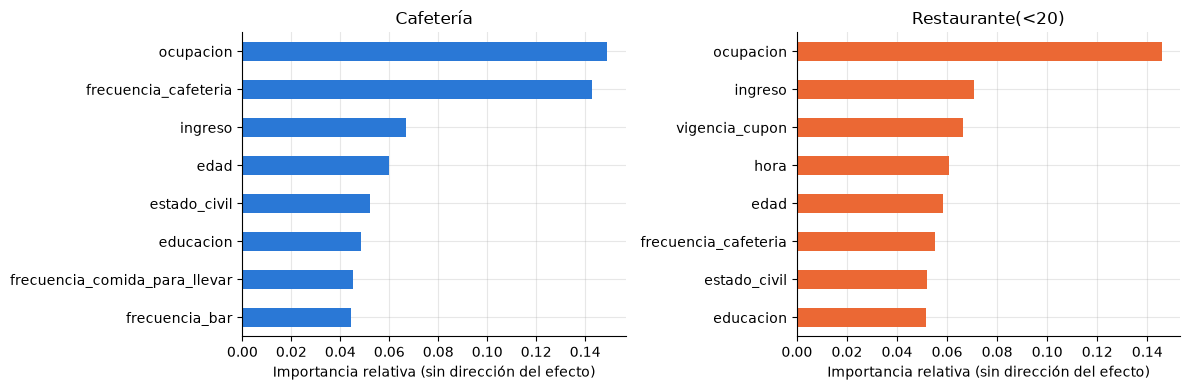

In [33]:
importancias = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, cupon in zip(axes, CUPONES):
    bosque = modelos[cupon][seleccion[cupon]]
    columnas = bosque.named_steps['preprocesamiento']
    if isinstance(columnas, Pipeline):
        columnas = columnas.named_steps['columnas']
    categorias = columnas.named_transformers_['nominales'].named_steps['codificar'].categories_
    variables = list(ORDINALES) + [c for c, valores in zip(NOMINALES, categorias) for _ in valores] + NUMERICAS
    pesos = bosque.named_steps['modelo'].feature_importances_
    importancia = pd.Series(pesos, index=variables).groupby(level=0).sum().sort_values(ascending=False)
    importancias[cupon] = importancia
    importancia.head(8).sort_values().plot.barh(ax=ax, color=COLOR[cupon])
    ax.set_title(cupon)
    ax.set_xlabel('Importancia relativa (sin dirección del efecto)')
    importancia.to_csv(RESULTADOS/f'importancias_{CUPONES.index(cupon)}.csv')
plt.tight_layout()
plt.show()


## Análisis de resultados

Las ocho respuestas siguientes se basan en los resultados anteriores.

### 1. ¿Qué características están más relacionadas con la aceptación?

En **Cafetería**, las mayores importancias del bosque son ocupacion (0.149), frecuencia_cafeteria (0.143), ingreso (0.067). La frecuencia de visita muestra una asociación clara: en entrenamiento, quienes nunca van aceptan 19.4% (n=736), frente a 69.3% (n=430) entre quienes van de cuatro a ocho veces al mes.

En **Restaurante(<20)** destacan ocupacion (0.146), ingreso (0.071), vigencia_cupon (0.066). La vigencia describe la oportunidad de aprovechar la oferta: con dos horas se acepta 59.1% (n=1140), frente a 83.1% (n=1075) con un día. La ocupación también puede recoger hábitos y contexto del conductor, pero su alta importancia debe interpretarse con cautela por tener muchas categorías.

Estas tasas muestran asociaciones, no causas. La importancia del bosque no indica por sí sola si aumentar una variable favorece o reduce la aceptación.

### 2. ¿Existen variables redundantes o poco informativas?

Se eliminaron `vehiculo`, casi vacía; `tiempo_cupon_mayor_5min`, constante; `direccion_opuesta`, complemento de `misma_direccion`; y `cupon`, constante una vez separados los modelos. Estas decisiones están respaldadas por las tablas de exploración.

Las distancias de 15 y 25 minutos están relacionadas, pero distinguen niveles diferentes y se conservaron. Algo similar sucede con clima y temperatura, y con destino y hora. Una importancia baja no prueba irrelevancia: una variable puede compartir información con otra. No se eliminan nuevas variables usando los resultados de test.

### 3. ¿Difieren los modelos entre Cafetería y Restaurante?

Sí. El modelo seleccionado para Cafetería alcanza F1 macro de test **0.778**, con recalls de No y Sí de **0.777** y **0.778**. Para Restaurante, el seleccionado alcanza **0.704**, con recalls de **0.500** y **0.885**.

Cafetería tiene clases casi equilibradas y más escenarios limpios (3.979 frente a 2.769). En Restaurante alrededor del 71% acepta, lo que facilita reconocer Sí pero dificulta detectar No. Además, cambian los hábitos y condiciones relevantes. Son explicaciones plausibles de la diferencia, no efectos causales aislados. La tabla muestra que los bosques mejoran el F1 macro de los árboles individuales y de logística.

### 4. ¿Mejoró el balanceo el modelo de Restaurante?

Con SMOTENC, el F1 macro de test pasa de **0.675 a 0.704** y el recall de la minoritaria No de **0.395 a 0.500**. El F1 ponderado pasa de 0.747 a 0.763. Sin embargo, el recall de Sí baja de 0.923 a 0.885, su F1 cambia de 0.850 a 0.846 y la precisión de No pasa de 0.681 a 0.643.

En CV, el F1 macro es **0.699 sin balanceo** y **0.709 con balanceo**. Se recomienda usar SMOTENC en esta comparación, según la métrica primaria de CV. Detectar más rechazos ayuda a evitar ofertas irrelevantes, pero perder aceptaciones implica omitir oportunidades. La mejora debe confirmarse en más datos; no se afirma significancia estadística.

### 5. ¿Cómo ayudan las importancias a explicar la aceptación o el rechazo?

Las gráficas permiten identificar qué variables utiliza más cada bosque. En Cafetería destaca el hábito de visitar cafeterías; en Restaurante la vigencia tiene un papel relevante junto con variables del perfil. Las tasas de entrenamiento muestran que nunca visitar cafeterías se asocia con mayor rechazo, y que disponer de un día para usar el cupón de Restaurante se asocia con mayor aceptación.

Esta interpretación ayuda a Ruta Alpes a entender la afinidad por el lugar y la oportunidad de aprovechar la oferta. Su límite es que la importancia es global, no tiene signo y puede favorecer variables con muchas categorías, como ocupación. No equivale a una regla exacta para un conductor ni demuestra causalidad; variables correlacionadas pueden repartirse la importancia.

### 6. ¿Cómo se integraría el modelo en la aplicación en tiempo real?

La aplicación construye el escenario, identifica el tipo de cupón y aplica el pipeline entrenado para obtener una puntuación de aceptación. Debe validar campos y categorías, limitar la frecuencia de notificaciones y mostrar ofertas únicamente en momentos seguros, por ejemplo cuando el vehículo está detenido.

El umbral comercial debe elegirse con validación adicional según el costo de molestar al usuario y de omitir una oportunidad. Si se comparan probabilidades de ambos modelos, primero debe evaluarse su calibración, especialmente después del balanceo. Un piloto permite medir aceptación y molestias reales; luego se monitorean cambios en los datos y desempeño antes de reentrenar.

### 7. ¿Qué limitaciones tiene decidir ofertas según el perfil demográfico?

Los bosques presentan F1 macro de entrenamiento cercano a 0,999, superior al de validación: existe sobreajuste. La preferencia por ellos se sustenta en CV, no en memorizar entrenamiento. Además, no hay identificadores de conductor para separar personas entre entrenamiento y prueba, y la aceptación declarada en una encuesta puede diferir de una compra real.

Edad, ingreso o estado civil no representan completamente a una persona y algunos grupos tienen poca información. La imputación por moda y los rangos amplios pueden ocultar diferencias. Tampoco se ha demostrado representatividad de los usuarios locales. La personalización requiere revisar privacidad, necesidad de los datos, transparencia y opciones del usuario. La exploración inicial y los resultados de test ya se inspeccionaron durante el desarrollo, por lo que no se presenta este test como una evaluación externa completamente ciega.

### 8. ¿Qué sesgos pueden existir y qué implicaría usar el modelo para precios dinámicos?

Puede existir **sesgo de selección y representación**: la encuesta original de Amazon Mechanical Turk no necesariamente representa a todos los conductores y algunos grupos son pequeños. También hay **sesgo de medición y respuesta**, porque ingreso, hábitos y aceptación hipotética son autorreportados. El modelo puede aprender estas diferencias a partir de edad, género, estado civil e ingreso, o de sus proxies, como ocupación y educación.

Además, se puede crear un ciclo de retroalimentación: un grupo recibe menos ofertas y se recoge menos evidencia de sus preferencias. Quitar los atributos demográficos no garantiza eliminar estos sesgos; antes de producción se recomienda evaluar errores y oportunidades por grupo.

Para precios dinámicos el perjuicio sería mayor: cobrar distinto según la capacidad de pago inferida puede producir desigualdades difíciles de detectar. Predecir aceptación no permite inferir automáticamente cuánto pagaría alguien ni justifica usar el modelo para fijar precios individuales. Ese uso necesitaría una evaluación específica.

## Recomendación final

Se recomienda **Random Forest para Cafetería** y **Random Forest + SMOTENC para Restaurante(<20)**, seleccionados por F1 macro de validación cruzada. En test obtienen **0.778** y **0.704**, respectivamente.

Para Cafetería el desempeño es equilibrado entre aceptar y rechazar. En Restaurante, el balanceo mejora la detección de rechazos, pero sacrifica algunas aceptaciones. Se acepta ese intercambio provisionalmente por su resultado de CV; el umbral y los costos comerciales requieren una validación posterior. La brecha de sobreajuste y la falta de evaluación por conductor limitan la generalización.

## Predicciones sobre los datos sin etiqueta

Se reentrena el ganador de CV de cada cupón con todos sus datos etiquetados limpios. Se conserva el orden y todas las columnas del archivo original y se añade `acepta_cupon`. No se calcula un F1 de estas veinte filas porque no conocemos sus etiquetas.

In [34]:
salida = prueba.copy()
salida['acepta_cupon'] = ''
for cupon in CUPONES:
    X, y = preparar_subconjunto(cupon)
    final = clone(modelos[cupon][seleccion[cupon]]).fit(X, y)
    mascara = prueba['cupon'].eq(cupon)
    salida.loc[mascara, 'acepta_cupon'] = np.where(final.predict(limpiar(prueba.loc[mascara])) == 1, 'Sí', 'No')
assert salida.drop(columns='acepta_cupon').equals(prueba)
assert len(salida) == 20 and salida['acepta_cupon'].isin(['Sí', 'No']).all()
salida.to_csv('Lab3_datos_Prueba.csv', index=False, encoding='utf-8-sig')
display(salida[['cupon', 'acepta_cupon']])
print('CSV exportado con 20 predicciones completas.')


,cupon,acepta_cupon
0,Cafetería,Sí
1,Cafetería,Sí
2,Cafetería,Sí
3,Cafetería,Sí
4,Restaurante(<20),Sí
5,Restaurante(<20),Sí
6,Restaurante(<20),No
7,Restaurante(<20),Sí
8,Restaurante(<20),Sí
9,Cafetería,No


CSV exportado con 20 predicciones completas.


## Uso de herramientas de IA generativa

Sección a completar por los integrantes: herramienta, uso, prompts, análisis crítico y aportes propios. El video de máximo tres minutos también queda a cargo de los integrantes.